Calculating inertia across different cluster sizes...


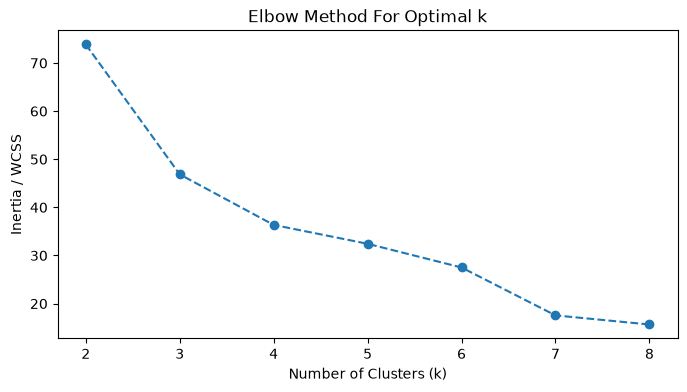

-> Look at the graph above. Pick the 'k' where the drop goes from steep to flat.

=== K-Means Evaluation Metrics (k=3) ===
Silhouette Score:      0.3768
Davies-Bouldin Index:  0.9726

=== Cluster Profile (Average values per group) ===
                      area     rooms          price
Cluster_Label                                      
0              1403.238095  2.619048  256057.095238
1              3480.000000  3.857143  577371.142857
2              2116.000000  3.526316  346347.263158


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

df= pd.read_csv("house_price.csv")
# ==========================================
# 1. Prepare and Scale the Data
# ==========================================
# Select only numerical features for clustering (K-Means uses distance calculations)
# If you ran the 21-column reset code earlier, all your columns are numerical now.
# We exclude the 'Churn' column so the algorithm finds hidden patterns naturally.
X = df.drop(columns=["Churn"], errors="ignore")

# Scale features so they all share an equal weight (Mean=0, Variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==========================================
# 2. Determine Best Number of Clusters (Elbow Method)
# ==========================================
print("Calculating inertia across different cluster sizes...")
inertia_values = []
cluster_range = range(2, 9)  # Test anywhere from 2 to 8 groups

for k in cluster_range:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init="auto")
    kmeans_test.fit(X_scaled)
    inertia_values.append(kmeans_test.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(cluster_range, inertia_values, marker="o", linestyle="--")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method For Optimal k")
plt.show()
print(
    "-> Look at the graph above. Pick the 'k' where the drop goes from steep to flat."
)

# ==========================================
# 3. Train the Final K-Means Model
# ==========================================
# We will assume an optimal k=3 for this run, adjust based on your elbow graph
optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init="auto")

# Fit the model and predict the cluster label for each row simultaneously
cluster_assignments = final_kmeans.fit_predict(X_scaled)

# Add the new cluster labels back into your original dataframe
df["Cluster_Label"] = cluster_assignments

# ==========================================
# 4. Unsupervised Evaluation Metrics
# ==========================================
print(f"\n=== K-Means Evaluation Metrics (k={optimal_k}) ===")

# Silhouette Score: Measures how close a data point is to its own cluster compared to others
# Range: -1 (bad) to +1 (perfect). Higher is better.
sil_score = silhouette_score(X_scaled, cluster_assignments)
print(f"Silhouette Score:      {sil_score:.4f}")

# Davies-Bouldin Index: Measures cluster separation and tightness
# Lower values indicate better clustering (0 is ideal).
db_index = davies_bouldin_score(X_scaled, cluster_assignments)
print(f"Davies-Bouldin Index:  {db_index:.4f}")

# ==========================================
# 5. Profile the Generated Clusters
# ==========================================
print("\n=== Cluster Profile (Average values per group) ===")
# See what makes each customer segment unique!
profile = df.groupby("Cluster_Label")[["area", "rooms", "price"]].mean()
print(profile)
